In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import linregress
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from scipy.optimize import curve_fit
from scipy.integrate import quad
from uncertainties import ufloat
from uncertainties import unumpy as unp

In [76]:
one_year_sec = 3600*24*365

In [77]:
# 0.5 mm window
R = 292.1/2

#First Pumpdown
Deflection = np.array([50.5, 52.1, 54.7, 56.3, 56.6, 58.8, 61.6, 63.7, 64.0, 64.1, 64.4, 64.5, 65.6, 66.3, 66.3, 66.5])-1.1-7 #mm
Deflection = unp.uarray(Deflection, 0.1)
time_strings = np.array([
    '2025-03-03T15:44', '2025-03-03T15:53', '2025-03-03T16:13', 
    '2025-03-03T16:38', '2025-03-03T16:44', '2025-03-03T18:06',  
    '2025-03-03T21:33', '2025-03-04T13:03', '2025-03-04T16:23',
    '2025-03-05T10:44','2025-03-05T14:32', '2025-03-05T16:13',
    '2025-03-06T16:52','2025-03-07T16:58', '2025-03-10T16:01', 
    '2025-03-11T17:21'
], dtype='datetime64')

#Second pumpdown
Deflection2 = np.array([52.7, 53.5, 54.8, 58.2, 59.2, 61.57, 62.1, 62.4, 62.9, 62.96, 62.98, 63.1, 63.1, 63.1, 63.6])-7
Deflection2 = unp.uarray(Deflection2, 0.1)
time_strings2 = np.array([
    '2025-03-24T17:21', '2025-03-24T17:25', '2025-03-24T17:31', 
    '2025-03-24T18:46', '2025-03-24T20:15', '2025-03-25T10:10', 
    '2025-03-25T14:13', '2025-03-25T16:57', '2025-03-26T11:15',
    '2025-03-26T13:05', '2025-03-27T15:15', '2025-03-28T14:59', 
    '2025-03-29T15:10', '2025-03-30T18:19', '2025-03-31T16:56'
], dtype='datetime64')

#Third pumpdown
Deflection3 = np.array([56.0, 57.6, 58.9, 59.8, 59.9, 60.6, 60.7, 61.4, 61.8, 62.8, 63.1, 63.2])-7
Deflection3 = unp.uarray(Deflection3, 0.1)
time_strings3 = np.array([
    '2025-04-02T09:46', '2025-04-02T09:59', '2025-04-02T10:25',
    '2025-04-02T11:01', '2025-04-02T11:14', '2025-04-02T12:00',
    '2025-04-02T13:17', '2025-04-02T16:05', '2025-04-02T18:01',
    '2025-04-03T16:39', '2025-04-04T13:26', '2025-04-04T14:48'
], dtype='datetime64')


In [78]:
DeflectionRectangular_05 = np.array([18.4, 19.9 ,20.0, 20.7, 21.1, 21.5, 21.5, 21.6, 21.65, 23.1])-6.7
DeflectionRectangular_05 - unp.uarray(DeflectionRectangular_05, 0.1)

timeRectangular_05 = np.array([
    '2025-04-16T17:08', '2025-04-16T17:48', '2025-04-16T18:21', 
    '2025-04-16T23:44', '2025-04-17T16:21', '2025-04-18T13:26', 
    '2025-04-18T16:28', '2025-04-19T20:09', '2025-04-23T17:19',
    '2025-05-14T18:40'
], dtype='datetime64')

t0_Rectangular_05 = np.datetime64('2025-04-16T17:04', 's')
seconds_after_t0_Rectangular_05 = (timeRectangular_05-t0_Rectangular_05).astype(int)

In [79]:
#0.25mm on Rectangular arpeture
Deflection025 = np.array([23.4, 24.2, 24.6, 25.62, 26.8, 27.5, 27.75, 27.9, 28.0, 28.2, 28.65, 28.7])-6.7 #mm
Deflection025 = unp.uarray(Deflection025, 0.1)
time025 = np.array([
    '2025-04-04T18:06', '2025-04-04T18:15', '2025-04-04T18:31',
    '2025-04-04T19:04', '2025-04-04T22:11', '2025-04-05T14:34', 
    '2025-04-05T15:07', '2025-04-06T15:13', '2025-04-06T18:25',
    '2025-04-07T12:48', '2025-04-07T15:30', '2025-04-08T15:55'
], dtype='datetime64')

In [80]:
#0.25mm on Rectangular arpeture
t0_025 = np.datetime64('2025-04-04T17:58', 's')
seconds_after_t0_025 = (time025-t0_025).astype(int)
len(seconds_after_t0_025)

12

In [81]:
def ddhhmm2seconds(ddhhmm):
    """
    Convert an integer in the format ddhhmm (days, hours, minutes) into seconds.

    Parameters:
        ddhhmm (int): Integer in the format ddhhmm (e.g., 120530 for 12 days, 5 hours, 30 minutes).

    Returns:
        int: seconds.
    """
    # Extract days, hours, and minutes
    dd = ddhhmm // 10000        # Extract the days
    hh = (ddhhmm // 100) % 100  # Extract the hours
    mm = ddhhmm % 100           # Extract the minutes

    # Convert to seconds
    total_seconds = dd * 86400 + hh * 3600 + mm * 60
    return total_seconds

In [82]:
#0.8 mm

### first ever pump down on this plastic
time_obs = np.array([2328, 2339, 2350, 10010, 10040, 11445,
                      11615, 12315, 31405, 41415, 71430]) ## format as ddhhmm
deflect = np.array([39.5, 41.5, 41.5, 42.5, 43.5, 47, 47.5, 48, 48.5, 49, 50]) - 7  ## mm from refence wire, zero pressure at 7mm
deflect = unp.uarray(deflect, 0.1)

time_obs = ddhhmm2seconds(time_obs)
time_obs = time_obs-time_obs[0]


### second pumpdown on this plastic
time_obs_2 = np.array([1705,1715,1820,2130,2340, 11412, 22255]) ## format as ddhhmm
deflect_2 = np.array([48,49,49.5,50,50.4, 50.5, 50.5]) - 7  ## mm from refence wire, zero pressure at 7mm
deflect_2 = unp.uarray(deflect_2, 0.1)

time_obs_2 = ddhhmm2seconds(time_obs_2)
time_obs_2 = time_obs_2-time_obs_2[0]


In [83]:
#0.5 mm
t0 = np.datetime64('2025-03-03T15:37', 's')
seconds_after_t0 = (time_strings-t0).astype(int)
print(seconds_after_t0/3600/24)

t02 = np.datetime64('2025-03-24T17:16', 's')
seconds_after_t02 = (time_strings2-t02).astype(int)
print(seconds_after_t02/3600/24)

t03 = np.datetime64('2025-04-02T09:37', 's')
seconds_after_t03 = (time_strings3-t03).astype(int)
print(seconds_after_t03/3600)

[4.86111111e-03 1.11111111e-02 2.50000000e-02 4.23611111e-02
 4.65277778e-02 1.03472222e-01 2.47222222e-01 8.93055556e-01
 1.03194444e+00 1.79652778e+00 1.95486111e+00 2.02500000e+00
 3.05208333e+00 4.05625000e+00 7.01666667e+00 8.07222222e+00]
[3.47222222e-03 6.25000000e-03 1.04166667e-02 6.25000000e-02
 1.24305556e-01 7.04166667e-01 8.72916667e-01 9.86805556e-01
 1.74930556e+00 1.82569444e+00 2.91597222e+00 3.90486111e+00
 4.91250000e+00 6.04375000e+00 6.98611111e+00]
[ 0.15        0.36666667  0.8         1.4         1.61666667  2.38333333
  3.66666667  6.46666667  8.4        31.03333333 51.81666667 53.18333333]


In [84]:
# 0.25mm 

In [85]:
# --- Fit functions ---
def fit_log_linear(x_sec, y):
    log_x = np.log(x_sec)
    slope, intercept, *_ = linregress(log_x, y)
    return slope, intercept

In [86]:
# Pumpdown 1
slope1, intercept1 = fit_log_linear(seconds_after_t0, unp.nominal_values(Deflection))
x_fit1 = np.logspace(np.log10(min(seconds_after_t0)), np.log10(one_year_sec), 200)
y_fit1 = slope1 * np.log(x_fit1) + intercept1

# Pumpdown 2
slope2, intercept2 = fit_log_linear(seconds_after_t02, unp.nominal_values(Deflection2))
x_fit2 = np.logspace(np.log10(min(seconds_after_t02)), np.log10(one_year_sec), 200)
y_fit2 = slope2 * np.log(x_fit2) + intercept2

# Pumpdown 3
slope3, intercept3 = fit_log_linear(seconds_after_t03, unp.nominal_values(Deflection3))
x_fit3 = np.logspace(np.log10(min(seconds_after_t03)), np.log10(one_year_sec), 200)
y_fit3 = slope3 * np.log(x_fit3) + intercept3

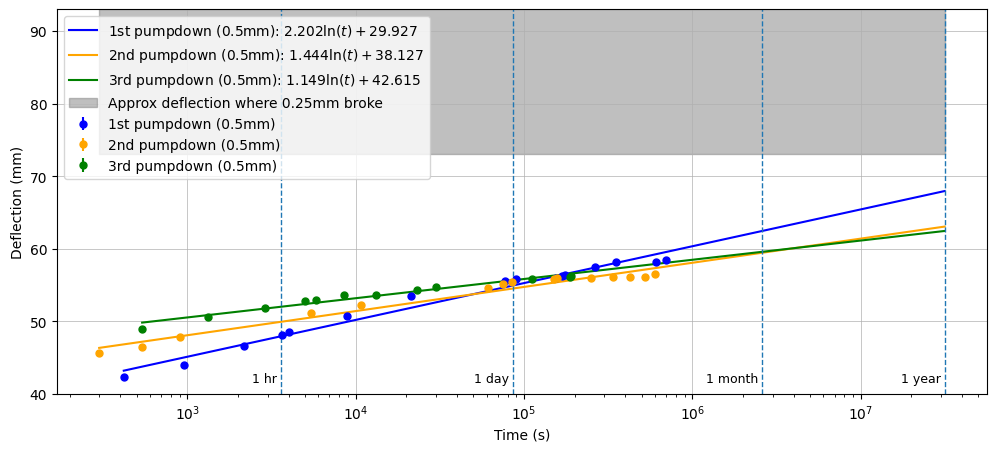

In [87]:
# --- Plotting ---
plt.figure(figsize=(12, 5))

plt.errorbar(seconds_after_t0, unp.nominal_values(Deflection), fmt='o', label='1st pumpdown (0.5mm)', yerr=unp.std_devs(Deflection), color='blue', markersize = 5)
plt.errorbar(seconds_after_t02, unp.nominal_values(Deflection2), fmt='o', label='2nd pumpdown (0.5mm)', yerr=unp.std_devs(Deflection2), color='orange',  markersize = 5)
plt.errorbar(seconds_after_t03, unp.nominal_values(Deflection3), fmt='o', label='3rd pumpdown (0.5mm)', yerr=unp.std_devs(Deflection3), color='green',  markersize = 5)

#lines
plt.plot(x_fit1, y_fit1, color='blue', linestyle='-', label=f'1st pumpdown (0.5mm): ${slope1:.3f}\\ln(t)+{intercept1:.3f}$')
plt.plot(x_fit2, y_fit2, color='orange', linestyle='-', label=f'2nd pumpdown (0.5mm): ${slope2:.3f}\\ln(t)+{intercept2:.3f}$')
plt.plot(x_fit3, y_fit3, color='green', linestyle='-', label=f'3rd pumpdown (0.5mm): ${slope3:.3f}\\ln(t)+{intercept3:.3f}$')

# Log scale on x-axis
plt.xscale('log')
plt.xlabel('Time (s)')
plt.ylabel('Deflection (mm)')
plt.grid(True, linestyle='-', linewidth=0.5)

# 1 hour line
plt.axvline(3600, linestyle='--', linewidth=1)
plt.text(3600 - 0.05*3600, 43, '1 hr', rotation=0, va='top', ha='right', fontsize=9)

# 1 day line
plt.axvline(86400, linestyle='--', linewidth=1)
plt.text(86400 - 0.05*86400, 43, '1 day', rotation=0, va='top', ha='right', fontsize=9)

# 1 month line (30 days)
plt.axvline(30 * 86400, linestyle='--', linewidth=1)
plt.text(30 * 86400 - 0.05 * 30 * 86400, 43, '1 month', rotation=0,  va='top', ha='right', fontsize=9)

# 1 year line
plt.axvline( 365 * 24 * 3600, linestyle='--', linewidth=1)
plt.text( 365 * 24 * 3600 - 0.05 *  365 * 24 * 3600, 43, '1 year', rotation=0, va='top', ha='right', fontsize=9)

# Define the y values for the two lines
x = np.linspace(np.min(seconds_after_t02), 365 * 24 * 3600, 100)
y1 = np.full_like(x, 80-7)
y2 = np.full_like(x, 100-7)

# Create the plot
plt.fill_between(x, y1, y2, color = 'grey', alpha=0.5, label='Approx deflection where 0.25mm broke')

plt.ylim(40,93)
plt.legend(loc = 'upper left')
plt.show()
plt.savefig('0.5mm3pumpdowns.png', dpi=200)
plt.close()  # Optional: closes the figure to avoid re-rendering

In [88]:
def arcsinh(x):
    return unp.log(x + (x**2 + 1)**(1/2))


#Calculate radial strain 0.5 mm
R_arc_05 = (1/2) * ((R**2 + 4 * Deflection**2)**(1/2) + (R**2 / (2 * Deflection)) * (arcsinh(2 * Deflection / R)))
R_strain_05 = (R_arc_05 - R)/R

R_arc_05_2 = (1/2) * ((R**2 + 4 * Deflection2**2)**(1/2) + (R**2 / (2 * Deflection2)) * (arcsinh(2 * Deflection2 / R)))
R_strain_05_2 = (R_arc_05_2 - R)/R

R_arc_05_3 = (1/2) * ((R**2 + 4 * Deflection3**2)**(1/2) + (R**2 / (2 * Deflection3)) * (arcsinh(2 * Deflection3 / R)))
R_strain_05_3 = (R_arc_05_3 - R)/R

In [89]:
R_025_broke_min = (1/2) * (np.sqrt(R**2 + 4 * 73**2) + (R**2 / (2 * 73)) * (np.arcsinh(2 * 73 / R)))
R_strain_025_broke_min = (R_025_broke_min-R)/R

R_025_broke_max = (1/2) * (np.sqrt(R**2 + 4 * 93**2) + (R**2 / (2 * 93)) * (np.arcsinh(2 * 93 / R)))
R_strain_025_broke_max = (R_025_broke_max-R)/R

In [90]:
x_fit1_strain = np.logspace(np.log10(min(seconds_after_t0)), np.log10(365 * 24 * 60 * 60), 1000)
x_fit2_strain = np.logspace(np.log10(min(seconds_after_t02)), np.log10(365 * 24 * 60 * 60), 1000)
x_fit3_strain = np.logspace(np.log10(min(seconds_after_t03)), np.log10(365 * 24 * 60 * 60), 1000)

y_fit1_strain = slope1 * np.log(x_fit1_strain) + intercept1
y_fit2_strain = slope2 * np.log(x_fit2_strain) + intercept2
y_fit3_strain = slope3 * np.log(x_fit3_strain) + intercept3

R_arc_05_fit = (1/2) * (np.sqrt(R**2 + 4 * y_fit1_strain**2) + (R**2 / (2 * y_fit1_strain)) * (np.arcsinh(2 * y_fit1_strain / R)))
R_strain_05_fit = (R_arc_05_fit - R) / R

R_arc_05_2_fit = (1/2) * (np.sqrt(R**2 + 4 * y_fit2_strain**2) + (R**2 / (2 * y_fit2_strain)) * (np.arcsinh(2 * y_fit2_strain / R)))
R_strain_05_2_fit = (R_arc_05_2_fit - R) / R

R_arc_05_3_fit = (1/2) * (np.sqrt(R**2 + 4 * y_fit3_strain**2) + (R**2 / (2 * y_fit3_strain)) * (np.arcsinh(2 * y_fit3_strain / R)))
R_strain_05_3_fit = (R_arc_05_3_fit - R) / R

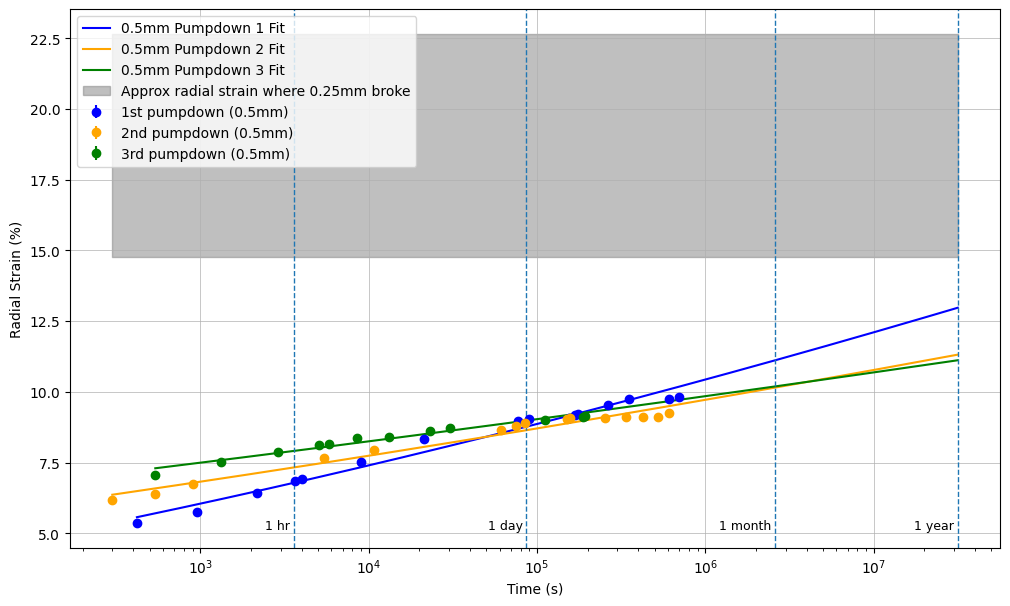

In [91]:
plt.figure(figsize=(12, 7))

plt.errorbar(seconds_after_t0, unp.nominal_values(R_strain_05)*100, fmt='o', label='1st pumpdown (0.5mm)', color='blue', yerr = unp.std_devs(R_strain_05)*100) 
plt.errorbar(seconds_after_t02, unp.nominal_values(R_strain_05_2)*100, fmt='o', label='2nd pumpdown (0.5mm)', color='orange', yerr = unp.std_devs(R_strain_05_2)*100) 
plt.errorbar(seconds_after_t03, unp.nominal_values(R_strain_05_3)*100, fmt='o', label='3rd pumpdown (0.5mm)', color='green', yerr = unp.std_devs(R_strain_05_3)*100) 
plt.plot(x_fit1_strain, R_strain_05_fit*100, '-', label='0.5mm Pumpdown 1 Fit', color = 'b')
plt.plot(x_fit2_strain, R_strain_05_2_fit*100, '-', label='0.5mm Pumpdown 2 Fit', color = 'orange')
plt.plot(x_fit3_strain, R_strain_05_3_fit*100, '-', label='0.5mm Pumpdown 3 Fit', color = 'green')


# 1 hour line
plt.axvline(3600, linestyle='--', linewidth=1)
plt.text(3600 - 0.05*3600, 5.5, '1 hr', rotation=0, va='top', ha='right', fontsize=9)

# 1 day line
plt.axvline(86400, linestyle='--', linewidth=1)
plt.text(86400 - 0.05*86400, 5.5, '1 day', rotation=0, va='top', ha='right', fontsize=9)

# 1 month line (30 days)
plt.axvline(30 * 86400, linestyle='--', linewidth=1)
plt.text(30 * 86400 - 0.05 * 30 * 86400, 5.5, '1 month', rotation=0,  va='top', ha='right', fontsize=9)

# 1 year line
plt.axvline( 365 * 24 * 3600, linestyle='--', linewidth=1)
plt.text( 365 * 24 * 3600 - 0.05 *  365 * 24 * 3600, 5.5, '1 year', rotation=0, va='top', ha='right', fontsize=9)

# Define the y values for the two lines
x = np.linspace(np.min(seconds_after_t02), 365 * 24 * 3600, 100)
y1 = np.full_like(x, R_strain_025_broke_min)
y2 = np.full_like(x, R_strain_025_broke_max)

# Create the plot
plt.fill_between(x, y1*100, y2*100, color = 'grey', alpha=0.5, label='Approx radial strain where 0.25mm broke')

plt.xscale('log')
#plt.ylim(4.5,22.5)
plt.xlabel('Time (s)')
plt.ylabel('Radial Strain (%)')
plt.grid(True, linestyle='-', linewidth=0.5)
# After plotting everything
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), loc = 'upper left')


In [92]:
# Pumpdown 1
slope08, intercept08 = fit_log_linear(time_obs[1:], unp.nominal_values(deflect[1:]))
x_fit08 = np.logspace(np.log10(time_obs[1]), np.log10(one_year_sec), 200)
y_fit08 = slope08 * np.log(x_fit08) + intercept08

# Pumpdown 2
slope08_2, intercept08_2 = fit_log_linear(time_obs_2[1:], unp.nominal_values(deflect_2[1:]))
x_fit08_2 = np.logspace(np.log10(time_obs_2[1]), np.log10(one_year_sec), 200)
y_fit08_2 = slope08_2 * np.log(x_fit08_2) + intercept08_2

(30.0, 93.0)

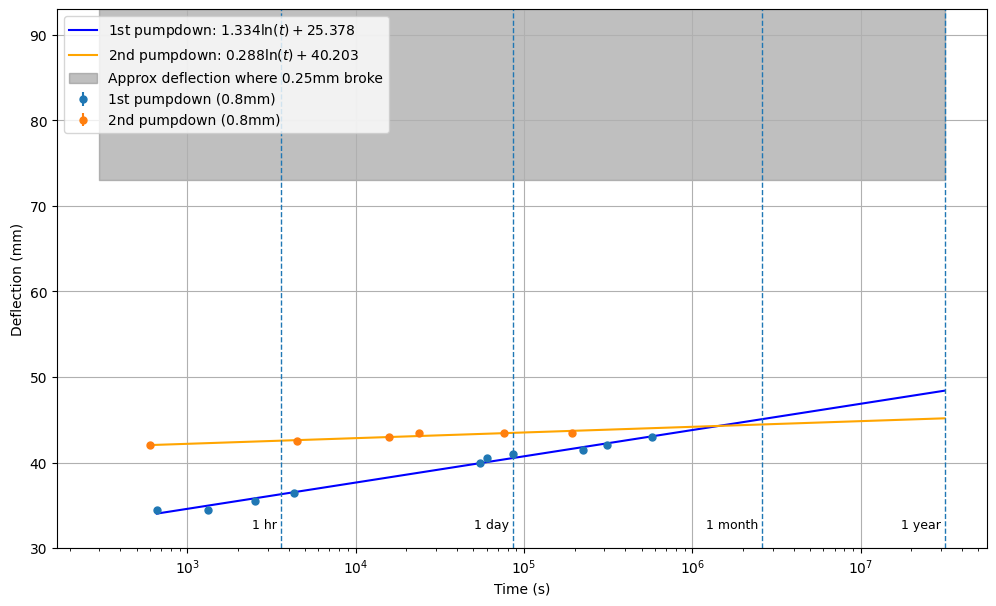

In [93]:
plt.figure(figsize=(12, 7))
plt.errorbar(time_obs, unp.nominal_values(deflect), fmt='o', label='1st pumpdown (0.8mm)', yerr= unp.std_devs(deflect), markersize = 5) 
plt.errorbar(time_obs_2, unp.nominal_values(deflect_2), fmt='o', label='2nd pumpdown (0.8mm)', yerr=unp.std_devs(deflect_2),  markersize = 5) 

plt.plot(x_fit08, y_fit08, color='blue', linestyle='-', label=f'1st pumpdown: ${slope08:.3f}\\ln(t)+{intercept08:.3f}$')
plt.plot(x_fit08_2, y_fit08_2, color='orange', linestyle='-', label=f'2nd pumpdown: ${slope08_2:.3f}\\ln(t)+{intercept08_2:.3f}$')

plt.xscale('log')
plt.xlabel('Time (s)')
plt.ylabel('Deflection (mm)')

plt.grid()

# 1 hour line
plt.axvline(3600, linestyle='--', linewidth=1)
plt.text(3600 - 0.05*3600, 32, '1 hr', rotation=0, va='bottom', ha='right', fontsize=9)

# 1 day line
plt.axvline(86400, linestyle='--', linewidth=1)
plt.text(86400 - 0.05*86400, 32, '1 day', rotation=0, va='bottom', ha='right', fontsize=9)

# 1 month line (30 days)
plt.axvline(30 * 86400, linestyle='--', linewidth=1)
plt.text(30 * 86400 - 0.05 * 30 * 86400, 32, '1 month', rotation=0,  va='bottom', ha='right', fontsize=9)

# 1 year line
plt.axvline( 365 * 24 * 3600, linestyle='--', linewidth=1)
plt.text( 365 * 24 * 3600 - 0.05 *  365 * 24 * 3600, 32, '1 year', rotation=0, va='bottom', ha='right', fontsize=9)

# fill area 0.25 mm broke
x = np.linspace(np.min(seconds_after_t02), 365 * 24 * 3600, 100)
y1 = np.full_like(x, 80-7)
y2 = np.full_like(x, 100-7)
plt.fill_between(x, y1, y2, color = 'grey', alpha=0.5, label='Approx deflection where 0.25mm broke')

plt.legend(loc = 'upper left')
plt.ylim(30,93)

In [94]:
#Calculate radial strain 0.8 mm
R_arc_08 = (1/2) * ((R**2 + 4 * deflect**2)**(1/2) + (R**2 / (2 * deflect)) * (arcsinh(2 * deflect / R)))
R_strain_08 = (R_arc_08 - R)/R

R_arc_08_2 = (1/2) * ((R**2 + 4 * deflect_2**2)**(1/2) + (R**2 / (2 * deflect_2)) * (arcsinh(2 * deflect_2 / R)))
R_strain_08_2 = (R_arc_08_2 - R)/R

In [95]:
x_fit08_strain = np.logspace(np.log10(time_obs[1]), np.log10(365 * 24 * 60 * 60), 1000)
x_fit08_2_strain = np.logspace(np.log10(time_obs_2[1]), np.log10(365 * 24 * 60 * 60), 1000)

y_fit08_strain = slope08 * np.log(x_fit08_strain) + intercept08
y_fit08_2_strain = slope08_2 * np.log(x_fit08_2_strain) + intercept08_2

R_arc_08_fit = (1/2) * (np.sqrt(R**2 + 4 * y_fit08_strain**2) + (R**2 / (2 * y_fit08_strain)) * (np.arcsinh(2 * y_fit08_strain / R)))
R_strain_08_fit = (R_arc_08_fit - R) / R

R_arc_08_2_fit = (1/2) * (np.sqrt(R**2 + 4 * y_fit08_2_strain**2) + (R**2 / (2 * y_fit08_2_strain)) * (np.arcsinh(2 * y_fit08_2_strain / R)))
R_strain_08_2_fit = (R_arc_08_2_fit - R) / R

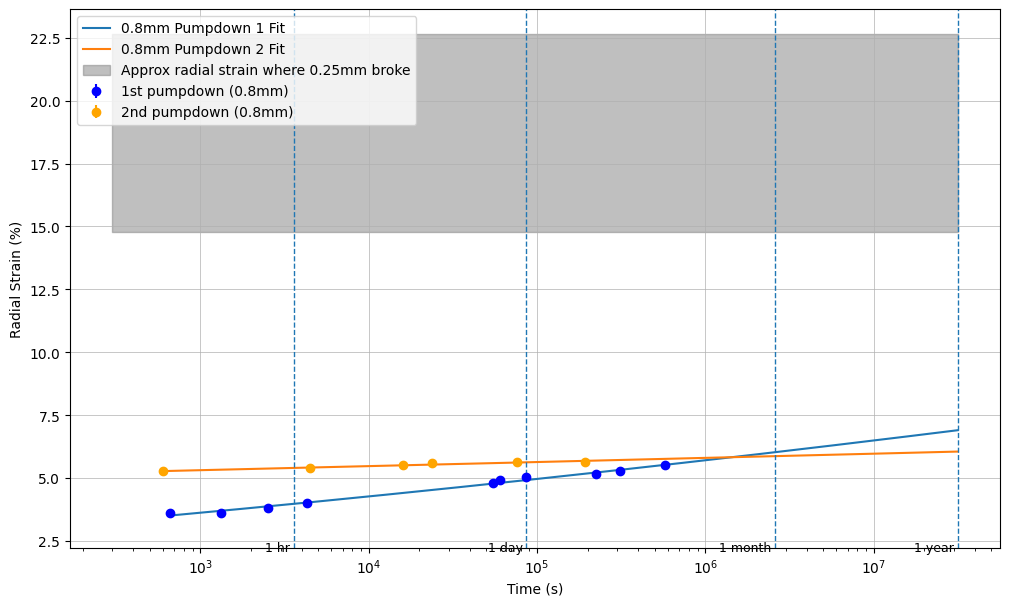

In [96]:
plt.figure(figsize=(12, 7))

plt.errorbar(time_obs, unp.nominal_values(R_strain_08)*100, fmt='o', label='1st pumpdown (0.8mm)', color='blue', yerr = unp.std_devs(R_strain_08)*100) #need to do error propagation
plt.errorbar(time_obs_2, unp.nominal_values(R_strain_08_2)*100, fmt='o', label='2nd pumpdown (0.8mm)', color='orange', yerr = unp.std_devs(R_strain_08_2)*100) #need to do error propagation

plt.plot(x_fit08_strain, R_strain_08_fit*100, '-', label='0.8mm Pumpdown 1 Fit')
plt.plot(x_fit08_2_strain, R_strain_08_2_fit*100, '-', label='0.8mm Pumpdown 2 Fit')


# 1 hour line
plt.axvline(3600, linestyle='--', linewidth=1)
plt.text(3600 - 0.05*3600, 2.5, '1 hr', rotation=0, va='top', ha='right', fontsize=9)

# 1 day line
plt.axvline(86400, linestyle='--', linewidth=1)
plt.text(86400 - 0.05*86400, 2.5, '1 day', rotation=0, va='top', ha='right', fontsize=9)

# 1 month line (30 days)
plt.axvline(30 * 86400, linestyle='--', linewidth=1)
plt.text(30 * 86400 - 0.05 * 30 * 86400, 2.5, '1 month', rotation=0,  va='top', ha='right', fontsize=9)

# 1 year line
plt.axvline( 365 * 24 * 3600, linestyle='--', linewidth=1)
plt.text( 365 * 24 * 3600 - 0.05 *  365 * 24 * 3600, 2.5, '1 year', rotation=0, va='top', ha='right', fontsize=9)

# Define the y values for the two lines
x = np.linspace(np.min(seconds_after_t02), 365 * 24 * 3600, 100)
y1 = np.full_like(x, R_strain_025_broke_min)
y2 = np.full_like(x, R_strain_025_broke_max)

# Create the plot
plt.fill_between(x, y1*100, y2*100, color = 'grey', alpha=0.5, label='Approx radial strain where 0.25mm broke')

plt.xscale('log')
plt.xlabel('Time (s)')
plt.ylabel('Radial Strain (%)')
plt.grid(True, linestyle='-', linewidth=0.5)
plt.legend(loc = 'upper left')

In [97]:
slope025, intercept025 = fit_log_linear(seconds_after_t0_025, unp.nominal_values(Deflection025))
x_fit025 = np.logspace(np.log10(seconds_after_t0_025), np.log10(one_year_sec), 200)
y_fit025 = slope025 * np.log(x_fit025) + intercept025

slopeRectangular_05, interceptRectangular_05 = fit_log_linear(seconds_after_t0_Rectangular_05, unp.nominal_values(DeflectionRectangular_05))
x_fitRectangular_05 = np.logspace(np.log10(seconds_after_t0_Rectangular_05), np.log10(one_year_sec), 200)
y_fitRectangular_05 = slopeRectangular_05* np.log(x_fitRectangular_05) + interceptRectangular_05

In [98]:
seconds_after_t0_Rectangular_05

array([    240,    2640,    4620,   24000,   83820,  159720,  170640,
        270300,  605700, 2424960])

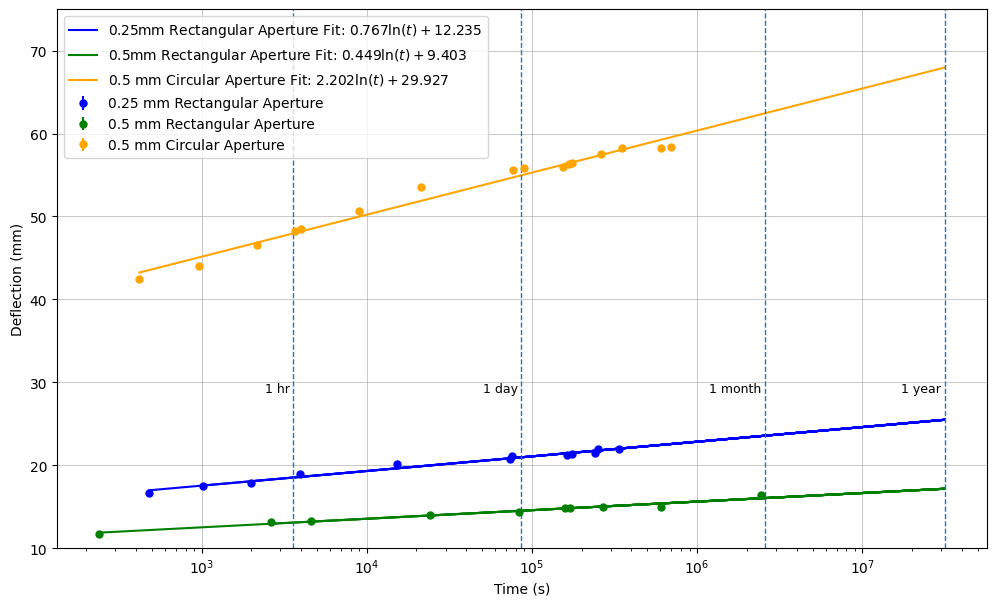

In [99]:
# --- Plotting ---
plt.figure(figsize=(12, 7))

plt.errorbar(seconds_after_t0_025, unp.nominal_values(Deflection025), fmt='o', label='0.25 mm Rectangular Aperture', yerr=unp.std_devs(Deflection025), color='blue', markersize = 5)
plt.errorbar(seconds_after_t0_Rectangular_05, unp.nominal_values(DeflectionRectangular_05), fmt='o', label='0.5 mm Rectangular Aperture', yerr=unp.std_devs(DeflectionRectangular_05), color='g', markersize = 5)
plt.errorbar(seconds_after_t0, unp.nominal_values(Deflection), fmt='o', label='0.5 mm Circular Aperture', yerr=unp.std_devs(Deflection), color='orange', markersize = 5)


#lines
plt.plot(x_fit025, y_fit025, color='blue', linestyle='-', label=f'0.25mm Rectangular Aperture Fit: ${slope025:.3f}\\ln(t)+{intercept025:.3f}$')
plt.plot(x_fitRectangular_05, y_fitRectangular_05, color='g', linestyle='-', label=f'0.5mm Rectangular Aperture Fit: ${slopeRectangular_05:.3f}\\ln(t)+{interceptRectangular_05:.3f}$')
plt.plot(x_fit1, y_fit1, color='orange', linestyle='-', label=f'0.5 mm Circular Aperture Fit: ${slope1:.3f}\\ln(t)+{intercept1:.3f}$')

# Log scale on x-axis
plt.xscale('log')
plt.xlabel('Time (s)')
plt.ylabel('Deflection (mm)')
plt.grid(True, linestyle='-', linewidth=0.5)

# 1 hour line
plt.axvline(3600, linestyle='--', linewidth=1)
plt.text(3600 - 0.05*3600, 30, '1 hr', rotation=0, va='top', ha='right', fontsize=9)

# 1 day line
plt.axvline(86400, linestyle='--', linewidth=1)
plt.text(86400 - 0.05*86400, 30, '1 day', rotation=0, va='top', ha='right', fontsize=9)

# 1 month line (30 days)
plt.axvline(30 * 86400, linestyle='--', linewidth=1)
plt.text(30 * 86400 - 0.05 * 30 * 86400, 30, '1 month', rotation=0,  va='top', ha='right', fontsize=9)

# 1 year line
plt.axvline( 365 * 24 * 3600, linestyle='--', linewidth=1)
plt.text( 365 * 24 * 3600 - 0.05 *  365 * 24 * 3600, 30, '1 year', rotation=0, va='top', ha='right', fontsize=9)

# Define the y values for the two lines
x = np.linspace(np.min(seconds_after_t02), 365 * 24 * 3600, 100)
y1 = np.full_like(x, 80-7)
y2 = np.full_like(x, 100-7)

#plt.fill_between(x, y1, y2, color = 'grey', alpha=0.5, label='Approx deflection where 0.25mm broke')

# After plotting everything
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), loc = 'upper left')
plt.ylim(10,75)
plt.savefig('0valApertures.png', dpi=200)

In [100]:
#0.25 mm in Rectangular aperture
R1 = 70/2
R_arc_025 = (1/2) * ((R1**2 + 4 * Deflection025**2)**(1/2) + (R1**2 / (2 * Deflection025)) * (arcsinh(2 * Deflection025 / R1)))
R_strain_025 = (R_arc_025 - R1)/R

In [101]:
x_fit025_strain = np.logspace(np.log10(seconds_after_t0_025), np.log10(365 * 24 * 60 * 60), 1000)
y_fit025_strain = slope025 * np.log(x_fit025_strain) + intercept025

R_arc_025_fit = (1/2) * (np.sqrt(R1**2 + 4 * y_fit025_strain**2) + (R1**2 / (2 * y_fit025_strain)) * (np.arcsinh(2 * y_fit025_strain / R1)))
R_strain025_fit = (R_arc_025_fit - R1) / R

In [102]:
#0.5 mm in Rectangular aperture
R_arc_Rectangular_05 = (1/2) * ((R1**2 + 4 * DeflectionRectangular_05**2)**(1/2) + (R1**2 / (2 * DeflectionRectangular_05)) * (arcsinh(2 * DeflectionRectangular_05 / R1)))
R_strain_Rectangular_05 = (R_arc_Rectangular_05 - R1)/R

In [103]:
x_fit_Rectangular_05_strain = np.logspace(np.log10(seconds_after_t0_Rectangular_05), np.log10(365 * 24 * 60 * 60), 1000)
y_fit_Rectangular_05_strain = slopeRectangular_05 * np.log(x_fit_Rectangular_05_strain) + interceptRectangular_05

R_arc_Rectangular_05_fit = (1/2) * (np.sqrt(R1**2 + 4 * y_fit_Rectangular_05_strain**2) + (R1**2 / (2 * y_fit_Rectangular_05_strain)) * (np.arcsinh(2 * y_fit_Rectangular_05_strain / R1)))
R_strain_Rectangular_05_fit = (R_arc_Rectangular_05_fit - R1) / R

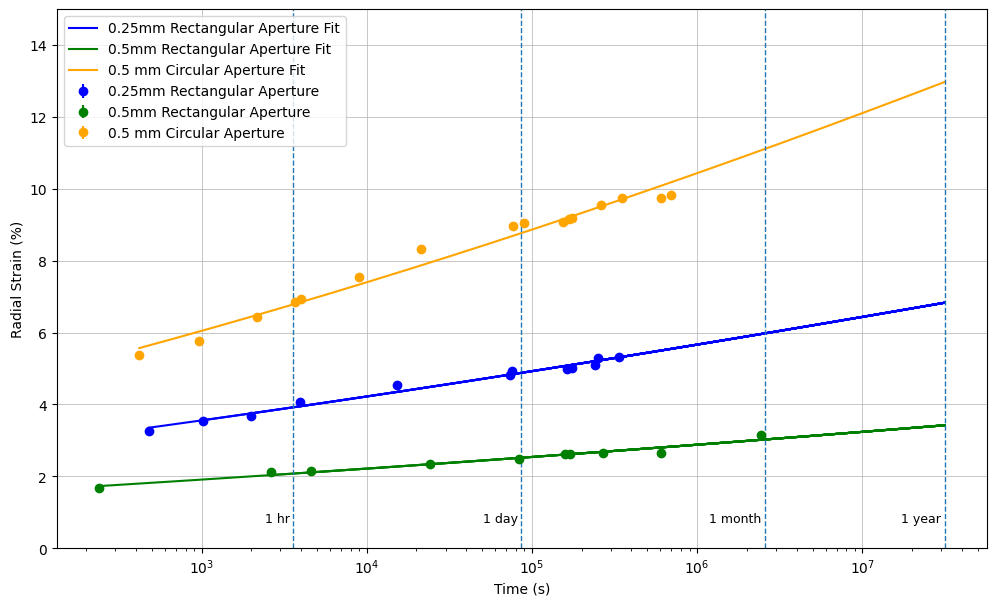

In [104]:
plt.figure(figsize=(12, 7))

plt.errorbar(seconds_after_t0_025, unp.nominal_values(R_strain_025)*100, fmt='o', label='0.25mm Rectangular Aperture', color='blue', yerr = unp.std_devs(R_strain_025)*100) #need to do error propagation
plt.plot(x_fit025_strain, R_strain025_fit*100, '-', label='0.25mm Rectangular Aperture Fit', color = 'b')

plt.errorbar(seconds_after_t0_Rectangular_05, unp.nominal_values(R_strain_Rectangular_05)*100, fmt='o', label='0.5mm Rectangular Aperture', color='g', yerr = unp.std_devs(R_strain_Rectangular_05)*100) #need to do error propagation
plt.plot(x_fit_Rectangular_05_strain, R_strain_Rectangular_05_fit*100, '-', label='0.5mm Rectangular Aperture Fit', color = 'g')

plt.errorbar(seconds_after_t0, unp.nominal_values(R_strain_05)*100, fmt='o', label='0.5 mm Circular Aperture', color='orange', yerr = unp.std_devs(R_strain_05)*100) 
plt.plot(x_fit1_strain, R_strain_05_fit*100, '-', label='0.5 mm Circular Aperture Fit', color = 'orange')


# 1 hour line
plt.axvline(3600, linestyle='--', linewidth=1)
plt.text(3600 - 0.05*3600, 1, '1 hr', rotation=0, va='top', ha='right', fontsize=9)

# 1 day line
plt.axvline(86400, linestyle='--', linewidth=1)
plt.text(86400 - 0.05*86400, 1, '1 day', rotation=0, va='top', ha='right', fontsize=9)

# 1 month line (30 days)
plt.axvline(30 * 86400, linestyle='--', linewidth=1)
plt.text(30 * 86400 - 0.05 * 30 * 86400, 1, '1 month', rotation=0,  va='top', ha='right', fontsize=9)

# 1 year line
plt.axvline( 365 * 24 * 3600, linestyle='--', linewidth=1)
plt.text( 365 * 24 * 3600 - 0.05 *  365 * 24 * 3600, 1, '1 year', rotation=0, va='top', ha='right', fontsize=9)

# Define the y values for the two lines
x = np.linspace(np.min(seconds_after_t02), 365 * 24 * 3600, 100)
y1 = np.full_like(x, R_strain_025_broke_min)
y2 = np.full_like(x, R_strain_025_broke_max)

# Create the plot
#plt.fill_between(x, y1*100, y2*100, color = 'grey', alpha=0.5, label='Approx radial strain where 0.25mm broke (circle)')

plt.ylim(0,15)
plt.xscale('log')
plt.xlabel('Time (s)')
plt.ylabel('Radial Strain (%)')
plt.grid(True, linestyle='-', linewidth=0.5)

handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), loc = 'upper left')

plt.savefig('0valAperturesStrain.png', dpi=200)

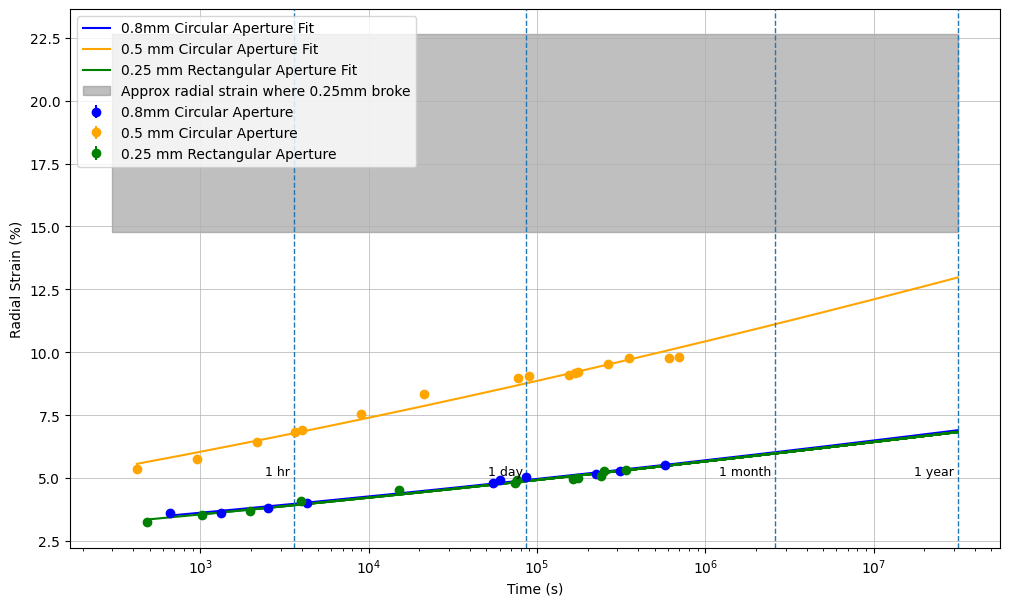

In [105]:
plt.figure(figsize=(12, 7))

plt.errorbar(time_obs, unp.nominal_values(R_strain_08)*100, fmt='o', label='0.8mm Circular Aperture', color='blue', yerr = unp.std_devs(R_strain_08)*100) #need to do error propagation
plt.plot(x_fit08_strain, R_strain_08_fit*100, '-', label='0.8mm Circular Aperture Fit', color = 'blue' )

plt.errorbar(seconds_after_t0, unp.nominal_values(R_strain_05)*100, fmt='o', label='0.5 mm Circular Aperture', color='orange', yerr = unp.std_devs(R_strain_05)*100) 
plt.plot(x_fit1_strain, R_strain_05_fit*100, '-', label='0.5 mm Circular Aperture Fit', color = 'orange')

plt.errorbar(seconds_after_t0_025, unp.nominal_values(R_strain_025)*100, fmt='o', label='0.25 mm Rectangular Aperture', color='green', yerr = unp.std_devs(R_strain_025)*100) 
plt.plot(x_fit025_strain, R_strain025_fit*100, '-', label='0.25 mm Rectangular Aperture Fit', color = 'green')

# 1 hour line
plt.axvline(3600, linestyle='--', linewidth=1)
plt.text(3600 - 0.05*3600, 5.5, '1 hr', rotation=0, va='top', ha='right', fontsize=9)

# 1 day line
plt.axvline(86400, linestyle='--', linewidth=1)
plt.text(86400 - 0.05*86400, 5.5, '1 day', rotation=0, va='top', ha='right', fontsize=9)

# 1 month line (30 days)
plt.axvline(30 * 86400, linestyle='--', linewidth=1)
plt.text(30 * 86400 - 0.05 * 30 * 86400, 5.5, '1 month', rotation=0,  va='top', ha='right', fontsize=9)

# 1 year line
plt.axvline( 365 * 24 * 3600, linestyle='--', linewidth=1)
plt.text( 365 * 24 * 3600 - 0.05 *  365 * 24 * 3600, 5.5, '1 year', rotation=0, va='top', ha='right', fontsize=9)

# Define the y values for the two lines
x = np.linspace(np.min(seconds_after_t02), 365 * 24 * 3600, 100)
y1 = np.full_like(x, R_strain_025_broke_min)
y2 = np.full_like(x, R_strain_025_broke_max)

# Create the plot
plt.fill_between(x, y1*100, y2*100, color = 'grey', alpha=0.5, label='Approx radial strain where 0.25mm broke')


plt.legend()
plt.xscale('log')
plt.xlabel('Time (s)')
plt.ylabel('Radial Strain (%)')
plt.grid(True, linestyle='-', linewidth=0.5)

handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), loc = 'upper left')

plt.savefig("All3Strain", dpi=200)

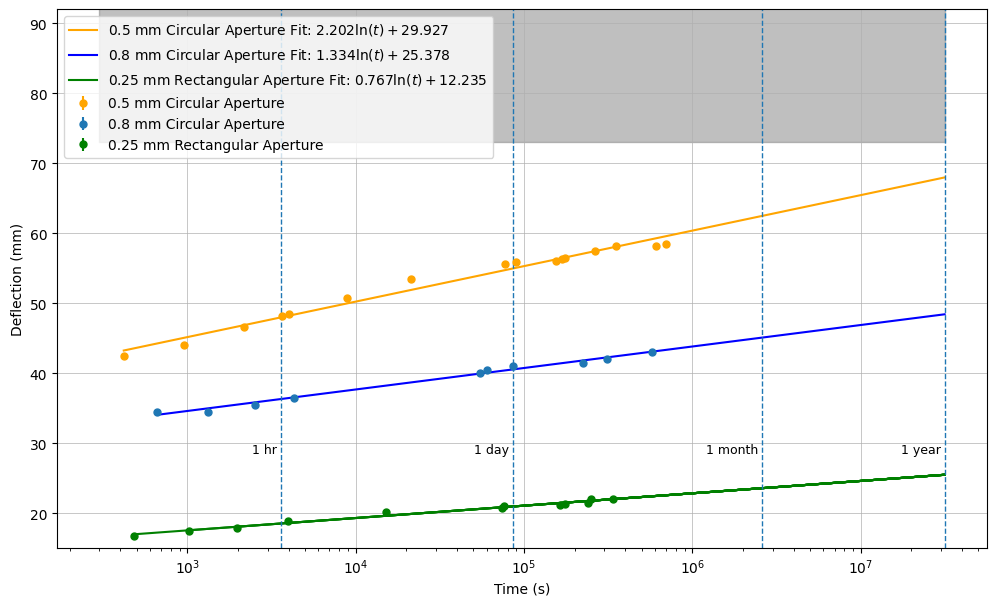

<Figure size 640x480 with 0 Axes>

In [106]:
# --- Plotting ---
plt.figure(figsize=(12, 7))

plt.errorbar(seconds_after_t0, unp.nominal_values(Deflection), fmt='o', label='0.5 mm Circular Aperture', yerr=unp.std_devs(Deflection), color='orange', markersize = 5)
plt.errorbar(time_obs, unp.nominal_values(deflect), fmt='o', label='0.8 mm Circular Aperture', yerr= unp.std_devs(deflect), markersize = 5) 
plt.errorbar(seconds_after_t0_025, unp.nominal_values(Deflection025), fmt='o', label='0.25 mm Rectangular Aperture', yerr=unp.std_devs(Deflection025), color='green', markersize = 5)

#lines

plt.plot(x_fit1, y_fit1, color='orange', linestyle='-', label=f'0.5 mm Circular Aperture Fit: ${slope1:.3f}\\ln(t)+{intercept1:.3f}$')
plt.plot(x_fit08, y_fit08, color='blue', linestyle='-', label=f'0.8 mm Circular Aperture Fit: ${slope08:.3f}\\ln(t)+{intercept08:.3f}$')
plt.plot(x_fit025, y_fit025, color='green', linestyle='-', label=f'0.25 mm Rectangular Aperture Fit: ${slope025:.3f}\\ln(t)+{intercept025:.3f}$')


# Log scale on x-axis
plt.xscale('log')
plt.xlabel('Time (s)')
plt.ylabel('Deflection (mm)')
plt.grid(True, linestyle='-', linewidth=0.5)

# 1 hour line
plt.axvline(3600, linestyle='--', linewidth=1)
plt.text(3600 - 0.05*3600, 30, '1 hr', rotation=0, va='top', ha='right', fontsize=9)

# 1 day line
plt.axvline(86400, linestyle='--', linewidth=1)
plt.text(86400 - 0.05*86400, 30, '1 day', rotation=0, va='top', ha='right', fontsize=9)

# 1 month line (30 days)
plt.axvline(30 * 86400, linestyle='--', linewidth=1)
plt.text(30 * 86400 - 0.05 * 30 * 86400, 30, '1 month', rotation=0,  va='top', ha='right', fontsize=9)

# 1 year line
plt.axvline( 365 * 24 * 3600, linestyle='--', linewidth=1)
plt.text( 365 * 24 * 3600 - 0.05 *  365 * 24 * 3600, 30, '1 year', rotation=0, va='top', ha='right', fontsize=9)

handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), loc = 'upper left')

# Define the y values for the two lines
x = np.linspace(np.min(seconds_after_t02), 365 * 24 * 3600, 100)
y1 = np.full_like(x, 80-7)
y2 = np.full_like(x, 100-7)

plt.ylim(15,92)
# Create the plot
plt.fill_between(x, y1, y2, color = 'grey', alpha=0.5, label='Approx deflection where 0.25mm broke')
plt.show()

plt.savefig("All3Def", dpi=200)


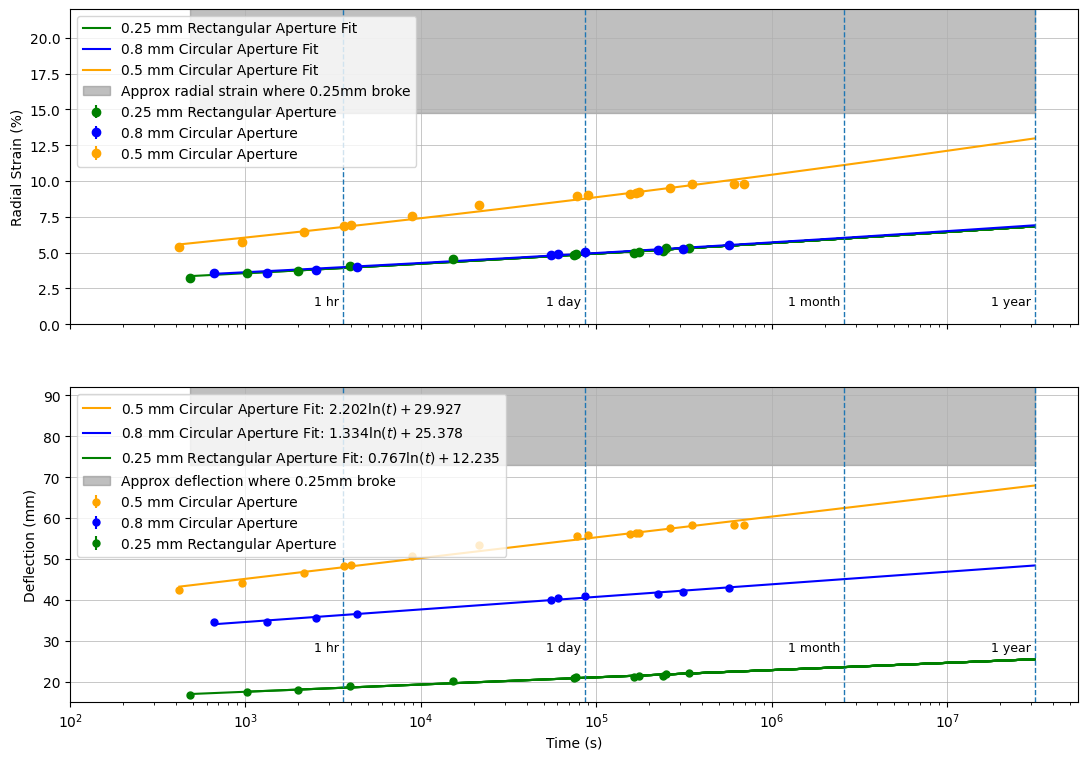

In [107]:

fig, axs = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

# --- Top Plot: Radial Strain ---
ax = axs[0]

# 0.25 mm Rectangular Aperture
ax.errorbar(seconds_after_t0_025, unp.nominal_values(R_strain_025) * 100, fmt='o', label='0.25 mm Rectangular Aperture', color='green', yerr=unp.std_devs(R_strain_025) * 100)
ax.plot(x_fit025_strain, R_strain025_fit * 100, '-', label='0.25 mm Rectangular Aperture Fit', color='green')

# 0.8 mm Circular Aperture
ax.errorbar(time_obs, unp.nominal_values(R_strain_08) * 100, fmt='o', label='0.8 mm Circular Aperture', color='blue', yerr=unp.std_devs(R_strain_08) * 100)
ax.plot(x_fit08_strain, R_strain_08_fit * 100, '-', label='0.8 mm Circular Aperture Fit', color='blue')

# 0.5 mm Circular Aperture
ax.errorbar(seconds_after_t0, unp.nominal_values(R_strain_05) * 100, fmt='o', label='0.5 mm Circular Aperture', color='orange', yerr=unp.std_devs(R_strain_05) * 100)
ax.plot(x_fit1_strain, R_strain_05_fit * 100, '-', label='0.5 mm Circular Aperture Fit', color='orange')

# Time markers
time_markers = [
    (3600, '1 hr'),
    (86400, '1 day'),
    (30 * 86400, '1 month'),
    (365 * 24 * 3600, '1 year')
]

for t, label in time_markers:
    ax.axvline(t, linestyle='--', linewidth=1)
    ax.text(t - 0.05 * t, 2, label, fontsize=9, ha='right', va='top')

# Shaded region
x_shade = np.linspace(np.min(seconds_after_t0_025), 365 * 24 * 3600, 100)
ax.fill_between(x_shade, R_strain_025_broke_min * 100, R_strain_025_broke_max * 100, color='grey', alpha=0.5, label='Approx radial strain where 0.25mm broke')

ax.set_ylabel('Radial Strain (%)')
ax.set_xscale('log')
ax.set_ylim(bottom=0)
ax.grid(True, linestyle='-', linewidth=0.5)
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='upper left')
ax.set_xlim(10e1)
ax.set_ylim(0,22)

# --- Bottom Plot: Deflection ---
ax = axs[1]

# Error bars
ax.errorbar(seconds_after_t0, unp.nominal_values(Deflection), fmt='o', label='0.5 mm Circular Aperture', yerr=unp.std_devs(Deflection), color='orange', markersize=5)
ax.errorbar(time_obs, unp.nominal_values(deflect), fmt='o', label='0.8 mm Circular Aperture', yerr=unp.std_devs(deflect), color='blue', markersize=5)
ax.errorbar(seconds_after_t0_025, unp.nominal_values(Deflection025), fmt='o', label='0.25 mm Rectangular Aperture', yerr=unp.std_devs(Deflection025), color='green', markersize=5)

# Fit lines
ax.plot(x_fit1, y_fit1, color='orange', linestyle='-', label=f'0.5 mm Circular Aperture Fit: ${slope1:.3f}\\ln(t)+{intercept1:.3f}$')
ax.plot(x_fit08, y_fit08, color='blue', linestyle='-', label=f'0.8 mm Circular Aperture Fit: ${slope08:.3f}\\ln(t)+{intercept08:.3f}$')
ax.plot(x_fit025, y_fit025, color='green', linestyle='-', label=f'0.25 mm Rectangular Aperture Fit: ${slope025:.3f}\\ln(t)+{intercept025:.3f}$')

# Time markers
for t, label in time_markers:
    ax.axvline(t, linestyle='--', linewidth=1)
    ax.text(t - 0.05 * t, 30, label, fontsize=9, ha='right', va='top')

# Shaded region
ax.fill_between(x_shade, 73, 93, color='grey', alpha=0.5, label='Approx deflection where 0.25mm broke')

ax.set_xlabel('Time (s)')
ax.set_ylabel('Deflection (mm)')
ax.set_xscale('log')
ax.set_ylim(15, 92)
ax.set_xlim(10e1)
ax.grid(True, linestyle='-', linewidth=0.5)
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='upper left')
plt.show()


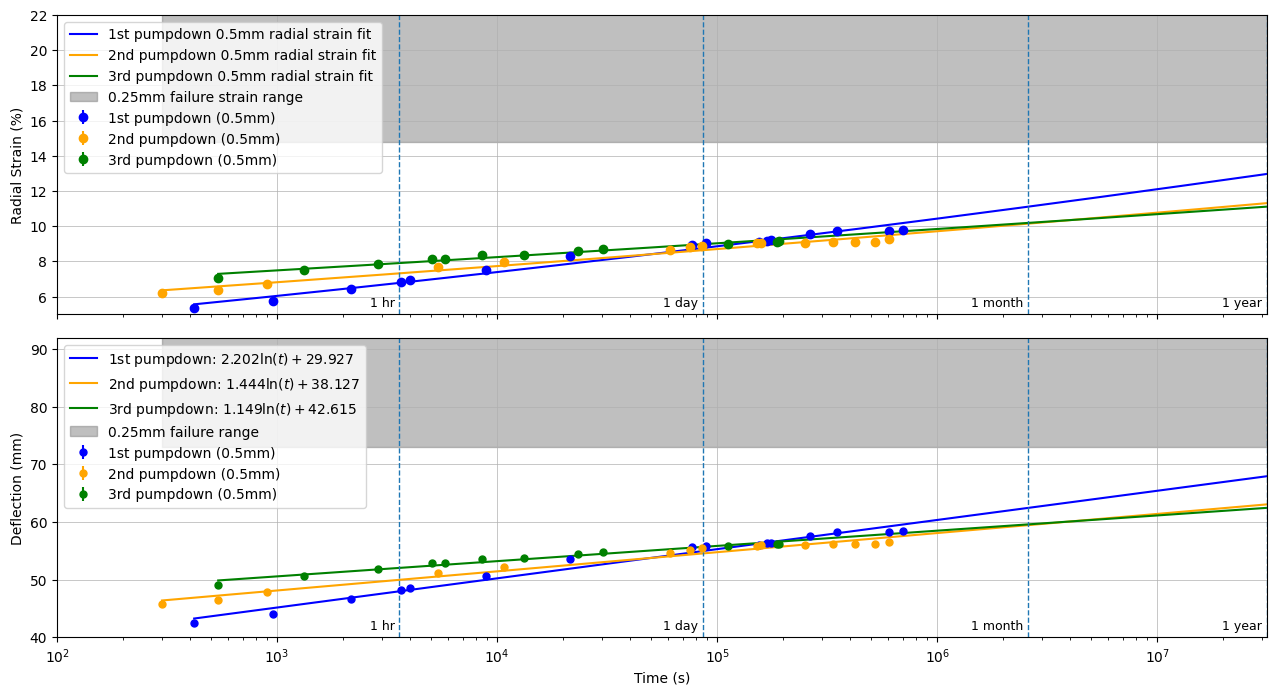

In [108]:
fig, (ax2, ax1) = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

# --- Plot 1: Deflection ---
ax1.errorbar(seconds_after_t0, unp.nominal_values(Deflection), fmt='o', label='1st pumpdown (0.5mm)', yerr=unp.std_devs(Deflection), color='blue', markersize=5)
ax1.errorbar(seconds_after_t02, unp.nominal_values(Deflection2), fmt='o', label='2nd pumpdown (0.5mm)', yerr=unp.std_devs(Deflection2), color='orange', markersize=5)
ax1.errorbar(seconds_after_t03, unp.nominal_values(Deflection3), fmt='o', label='3rd pumpdown (0.5mm)', yerr=unp.std_devs(Deflection3), color='green', markersize=5)

ax1.plot(x_fit1, y_fit1, color='blue', linestyle='-', label=f'1st pumpdown: ${slope1:.3f}\\ln(t)+{intercept1:.3f}$')
ax1.plot(x_fit2, y_fit2, color='orange', linestyle='-', label=f'2nd pumpdown: ${slope2:.3f}\\ln(t)+{intercept2:.3f}$')
ax1.plot(x_fit3, y_fit3, color='green', linestyle='-', label=f'3rd pumpdown: ${slope3:.3f}\\ln(t)+{intercept3:.3f}$')

# Reference bands
x = np.linspace(np.min(seconds_after_t02), 365 * 24 * 3600, 100)
y1 = np.full_like(x, 80 - 7)
y2 = np.full_like(x, 100 - 7)
ax1.fill_between(x, y1, y2, color='grey', alpha=0.5, label='0.25mm failure range')

# Vertical lines
for t, label in zip([3600, 86400, 30*86400, 365*24*3600], ['1 hr', '1 day', '1 month', '1 year']):
    ax1.axvline(t, linestyle='--', linewidth=1)
    ax1.text(t - 0.05*t, 43, label, ha='right', va='top', fontsize=9)

ax1.set_xscale('log')
ax1.set_ylim(40, 92)
ax1.set_xlim(10e1,one_year_sec)
ax1.set_ylabel('Deflection (mm)')
ax1.grid(True, linestyle='-', linewidth=0.5)
ax1.legend(loc='upper left')

# --- Plot 2: Radial Strain ---
ax2.errorbar(seconds_after_t0, unp.nominal_values(R_strain_05)*100, fmt='o', label='1st pumpdown (0.5mm)', color='blue', yerr=unp.std_devs(R_strain_05)*100)
ax2.errorbar(seconds_after_t02, unp.nominal_values(R_strain_05_2)*100, fmt='o', label='2nd pumpdown (0.5mm)', color='orange', yerr=unp.std_devs(R_strain_05_2)*100)
ax2.errorbar(seconds_after_t03, unp.nominal_values(R_strain_05_3)*100, fmt='o', label='3rd pumpdown (0.5mm)', color='green', yerr=unp.std_devs(R_strain_05_3)*100)

ax2.plot(x_fit1_strain, R_strain_05_fit*100, '-', color='b', label='1st pumpdown 0.5mm radial strain fit')
ax2.plot(x_fit2_strain, R_strain_05_2_fit*100, '-', color='orange', label='2nd pumpdown 0.5mm radial strain fit')
ax2.plot(x_fit3_strain, R_strain_05_3_fit*100, '-', color='green', label='3rd pumpdown 0.5mm radial strain fit')

y1 = np.full_like(x, R_strain_025_broke_min * 100)
y2 = np.full_like(x, R_strain_025_broke_max * 100)
ax2.fill_between(x, y1, y2, color='grey', alpha=0.5, label='0.25mm failure strain range')

for t, label in zip([3600, 86400, 30*86400, 365*24*3600], ['1 hr', '1 day', '1 month', '1 year']):
    ax2.axvline(t, linestyle='--', linewidth=1)
    ax2.text(t - 0.05*t, 6, label, ha='right', va='top', fontsize=9)
ax2.set_xlim(10e1,one_year_sec)
ax2.set_ylim(5,22)
ax2.set_xscale('log')
ax1.set_xlabel('Time (s)')
ax2.set_ylabel('Radial Strain (%)')
ax2.grid(True, linestyle='-', linewidth=0.5)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()


In [109]:
#0.25 mm Rectangular apeture + LN2 test
DeflectionRectangular_025_LN2_before = np.array([21.6, 23.9, 25.85, 26.9, 27.2])-6.7
DeflectionRectangular_025_LN2_during = np.array([27.4, 26.5])-6.7
DeflectionRectangular_025_LN2_after = np.array([27.2, 28.29])-6.7


timeRectangular_025_LN2_before = time_strings = np.array([
  '2025-04-16T18:12', '2025-04-16T19:02', '2025-04-17T01:19',
  '2025-04-17T10:49', '2025-04-17T17:14', 
], dtype='datetime64')
timeRectangular_025_LN2_during = time_strings = np.array([
  '2025-04-17T17:26','2025-04-17T17:42'
], dtype='datetime64')
timeRectangular_025_LN2_after = time_strings = np.array([
  '2025-04-17T18:01',  '2025-04-18T23:41'
], dtype='datetime64')

t0_Rectangular_022_LN2 = np.datetime64('2025-04-16T18:09', 's')
seconds_after_t0_Rectangular_022_LN2_before = (timeRectangular_025_LN2_before-t0_Rectangular_022_LN2).astype(int)
seconds_after_t0_Rectangular_022_LN2_during = (timeRectangular_025_LN2_during-t0_Rectangular_022_LN2).astype(int)
seconds_after_t0_Rectangular_022_LN2_after = (timeRectangular_025_LN2_after-t0_Rectangular_022_LN2).astype(int)

boil_off_sec = int((np.datetime64('2025-04-17T17:55', 's') - t0_Rectangular_022_LN2).astype(int))
room_temp_sec = int((np.datetime64('2025-04-17T17:59', 's') - t0_Rectangular_022_LN2).astype(int))

<>:16: SyntaxWarning: invalid escape sequence '\l'
<>:16: SyntaxWarning: invalid escape sequence '\l'
/var/folders/vx/92gqqjss3zsd40kfns0vpzg40000gn/T/ipykernel_56350/2886895772.py:16: SyntaxWarning: invalid escape sequence '\l'
  plt.plot(x_fit025, y_fit025, label=f'Fit: ${slope025:.3f}\ln(t)+{intercept025:.3f}$', color='purple', linestyle='-')


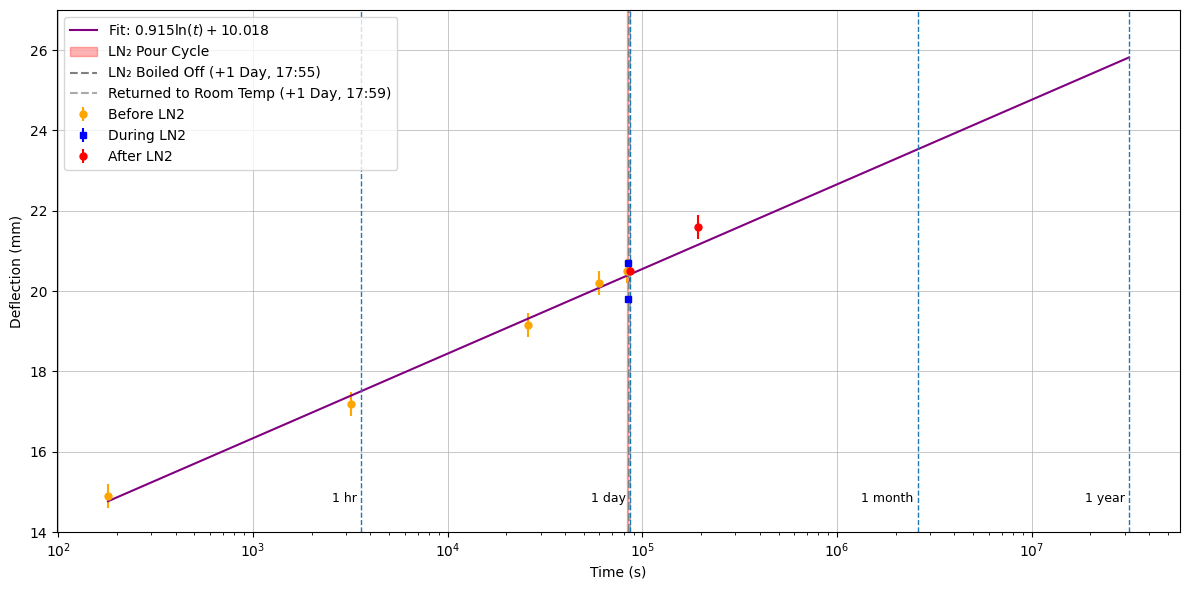

In [110]:
# Fit to the "before LN2" data
slope025, intercept025 = fit_log_linear(seconds_after_t0_Rectangular_022_LN2_before, DeflectionRectangular_025_LN2_before)

# Generate fit line over log-spaced time from min to 1 year
x_fit025 = np.logspace(np.log10(np.min(seconds_after_t0_Rectangular_022_LN2_before)), np.log10(365 * 24 * 3600), 200)
y_fit025 = slope025 * np.log(x_fit025) + intercept025

# Plot with fit line
plt.figure(figsize=(12, 6))

plt.errorbar(seconds_after_t0_Rectangular_022_LN2_before, DeflectionRectangular_025_LN2_before, fmt='o', label='Before LN2', yerr=0.3, markersize = 5, color = 'orange')
plt.errorbar(seconds_after_t0_Rectangular_022_LN2_during, DeflectionRectangular_025_LN2_during, fmt='s', label='During LN2', yerr= 0, markersize = 5, color = 'blue') 
plt.errorbar(seconds_after_t0_Rectangular_022_LN2_after, DeflectionRectangular_025_LN2_after, fmt='o', label='After LN2', yerr=0.3, markersize = 5, color = 'red')


plt.plot(x_fit025, y_fit025, label=f'Fit: ${slope025:.3f}\ln(t)+{intercept025:.3f}$', color='purple', linestyle='-')
# Add vertical shaded region to indicate LN2 pour time
plt.axvspan(
    seconds_after_t0_Rectangular_022_LN2_before[-1],
    seconds_after_t0_Rectangular_022_LN2_during[0],
    color='red',
    alpha=0.3,
    label='LN₂ Pour Cycle'
)

# Vertical lines for LN2 boil-off and return to room temp
plt.axvline(boil_off_sec, color='gray', linestyle='--', linewidth=1.5, label='LN₂ Boiled Off (+1 Day, 17:55)')
plt.axvline(room_temp_sec, color='darkgray', linestyle='--', linewidth=1.5, label='Returned to Room Temp (+1 Day, 17:59)')

# Time markers
for t, label in zip([3600, 86400, 30*86400, 365*24*3600], ['1 hr', '1 day', '1 month', '1 year']):
    plt.axvline(t, linestyle='--', linewidth=1)
    plt.text(t - 0.05*t, 15, label, ha='right', va='top', fontsize=9)

plt.xlabel('Time (s)')
plt.ylabel('Deflection (mm)')
plt.xscale('log')
plt.ylim(14,27)
plt.legend()
plt.grid(True, linestyle='-', linewidth=0.5)
plt.tight_layout()

plt.savefig("LN2Def", dpi=200)


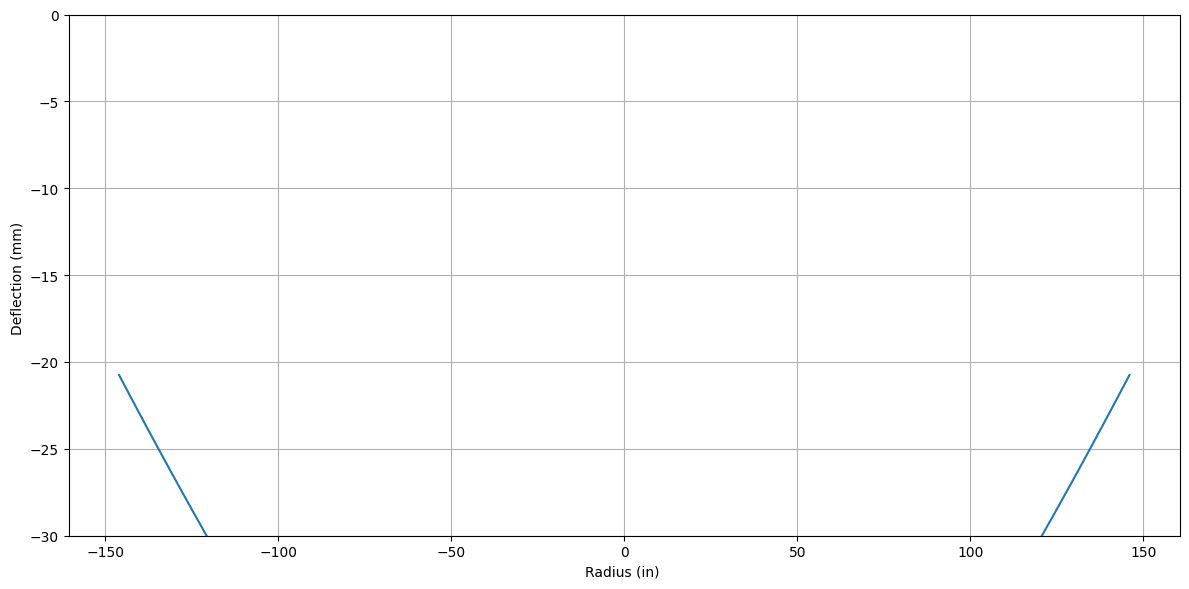

In [111]:


# Create deflection range (exclude zero)
deflect_pos = np.linspace(0.01,  292.1/2, 500)
R_arc_pos = 0.5 * (
    np.sqrt(R**2 + 4 * deflect_pos**2) +
    (R**2 / (2 * deflect_pos)) * np.arcsinh(2 * deflect_pos / R)
)

# Reflect to negative side
deflect_full = np.concatenate((-deflect_pos[::-1], deflect_pos))
R_arc_full = (np.concatenate((R_arc_pos[::-1], R_arc_pos))-257.5)/2

# Plot
plt.figure(figsize=(12, 6))
plt.plot(deflect_full, R_arc_full)
plt.xlabel("Radius (in) ")
plt.ylabel("Deflection (mm) ")
plt.grid(True)
plt.ylim(-30,0)
plt.tight_layout()
plt.show()
